# Favorita (quarterly): cost-based local subgroups — BS vs BUS vs two BUS→BS ensembles, with pruning
One of three Favorita notebooks that differ **only** in the time resolution of the target
(the hierarchy daily → monthly → quarterly). Everything else is identical, including the records
(same filter on daily-equivalent volume), descriptors and period, so the three can be compared directly.

- Records = store × product family series, 2015-01-01 to 2017-06-30 (identifiers only).
- Peers = the same family in other stores. Base window = all of 2015.
- Sales are **units**, not dollars (Favorita has no prices), so "cost" = volume.
- Descriptors: store attributes (type, cluster, city, customer transactions as level / trend / volatility),
  plus **record-level** promotion descriptors compared with the same family in other stores.
- Oil price and national holidays are the same for every store, so they cannot describe a subgroup.

In [1]:
import os
import time
import heapq
import itertools
from collections import Counter

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

In [2]:
DATASET = "favorita_quarterly"
QUICK = False          # True = tiny permutation / scaling runs, only to test the notebook end to end

# ---- Search parameters (Bart §6.3.1) ----
D_MAX = 3                # max conditions in a description
Q = 20                   # result set size
W = 50                   # beam width (BS, and the BS step of the pool ensemble)
U = 200                  # number of mini-clusters (pairs) for every BUS variant and both ensembles
POOL_SIZE = 30           # pool ensemble: conditions the BS step may use
W_MC = 5                 # per-mini-cluster ensemble: beam width of each small beam search

# ---- Narrow findings ----
MIN_COV = 0.02           # at least 2% of records
MAX_COV = 0.15           # at most 15% of records
MIN_STORES = 2           # a single odd store is not a pattern

# ---- Reference point (peer-expected sales) ----
BASE_LEN = None             # set in the data cell: all periods in 2015
MIN_BASE_LEVEL = None       # set in the data cell from MIN_DAILY_LEVEL
MIN_PEERS = 5            # at least 5 records of the same item (dept / family) to build a peer index
UNIT = "units"
PERIOD = "quarter"
RESOLUTION = "QE"   # D = daily, ME = month end, QE = quarter end
MIN_DAILY_LEVEL = 7         # units per day in 2015; converted to units per quarter in the data cell

# ---- Experiments ----
MEASURES = ["M1", "M2", "M3"]
METHODS = ["BS", "BUS", "BUS-α", "BUS→BS pool", "BUS→BS per-MC"]
NU = 10 if QUICK else 100                                   # permutation runs for the DFD
SCALING_FRACTIONS = [0.25, 1.0] if QUICK else [0.25, 0.5, 0.75, 1.0]
SCALING_SEEDS = [0] if QUICK else [0, 1, 2]
SEED = 0

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

In [3]:
START_DATE, END_DATE = "2015-01-01", "2017-06-30"   # whole quarters, so all three resolutions cover the same days

raw = pd.read_csv("final_sales_dataset.csv", usecols=["date", "store_nbr", "family", "sales", "onpromotion"],
                  parse_dates=["date"])
raw = raw[raw["date"].between(START_DATE, END_DATE)]

sales_daily = raw.pivot(index=["store_nbr", "family"], columns="date", values="sales").fillna(0).sort_index()
promo = raw.pivot(index=["store_nbr", "family"], columns="date", values="onpromotion").reindex_like(sales_daily).fillna(0)

# The hierarchy: same days, summed into months or quarters.
if RESOLUTION == "D":
    sales = sales_daily
else:
    sales = sales_daily.T.resample(RESOLUTION).sum().T
dates = pd.DatetimeIndex(sales.columns)
S = sales.to_numpy(dtype=float)

# Base window = all of 2015 at every resolution; the size filter uses the same daily-equivalent volume.
BASE_LEN = int((dates < "2016-01-01").sum())
base_days = int((sales_daily.columns < "2016-01-01").sum())
MIN_BASE_LEVEL = MIN_DAILY_LEVEL * base_days / BASE_LEN

records = sales.index.to_frame(index=False).rename(columns={"store_nbr": "store", "family": "item"})

# Store descriptors
stores_info = pd.read_csv("Store/stores.csv").set_index("store_nbr")[["type", "cluster", "city"]]
stores_info["cluster"] = stores_info["cluster"].astype(str)

transactions = pd.read_csv("Store/transactions.csv", parse_dates=["date"])
transactions = transactions[transactions["date"].between(START_DATE, END_DATE)]


def summarise_daily(group):
    days = (group["date"] - pd.Timestamp(START_DATE)).dt.days.to_numpy(dtype=float)
    y = group["transactions"].to_numpy(dtype=float)
    slope, intercept = np.polyfit(days, y, 1)
    residual = y - (slope * days + intercept)
    return pd.Series({"mean": y.mean(), "slope": slope * 365, "volatility": residual.std() / y.mean()})


tx_desc = transactions.groupby("store_nbr")[["date", "transactions"]].apply(summarise_daily)
tx_desc.columns = [f"transactions_{c}" for c in tx_desc.columns]

# Record-level promotion descriptors from the daily data (compared with the same family in other stores later)
t_days = np.arange(promo.shape[1], dtype=float)
t_days -= t_days.mean()
promo_values = promo.to_numpy(dtype=float)
records["promo_mean"] = promo_values.mean(axis=1)
records["promo_slope"] = (promo_values - promo_values.mean(axis=1, keepdims=True)) @ t_days / (t_days ** 2).sum() * 365

records = (records.merge(stores_info, left_on="store", right_index=True, how="left")
                  .merge(tx_desc, left_on="store", right_index=True, how="left"))
for column in tx_desc.columns:
    records[column] = records[column].fillna(records[column].median())

categorical_cols = ["type", "cluster", "city"]
continuous_cols = list(tx_desc.columns)
peer_relative_cols = ["promo_mean", "promo_slope"]
print(S.shape, records.shape, f"base window = {BASE_LEN} periods, min level = {MIN_BASE_LEVEL:.1f} units/period")

(1729, 10) (1729, 10) base window = 4 periods, min level = 637.0 units/period


## Reference point: peer-expected sales
For record *i* (a store's item: Walmart department / Favorita product family):

- **level_i** = its normal sales per period in the base window (Konijn's cost *c*).
- **peer index** = how the *same item in the other stores* moved, relative to their own normal level
  (leave-one-out, so a record is never compared with itself).
- **expected_i(t)** = level_i × peer index(t): what this record would have sold had it moved exactly like its peers.
- **e_i(t) = actual − expected**: the continuous, high-dimensional version of Konijn's *c · t*.
- **r_i(t) = e_i(t) / level_i**: the continuous version of the 0/1 target *t* (deviation as a share of own size).

Seasonality and product mix are inside the peer index, so they cancel out. Over the base window the
excess of every record sums to exactly 0, so anything that builds up afterwards is growth or decline
against peers, and anything inside the base window is a timing difference.

In [4]:
level = S[:, :BASE_LEN].mean(axis=1)
item = records["item"].astype(str).to_numpy()

# Keep records with a meaningful size and enough peers.
ok = level >= MIN_BASE_LEVEL
ok &= pd.Series(ok).groupby(item).transform("sum").to_numpy() >= MIN_PEERS

records = records[ok].reset_index(drop=True)
S, level, item = S[ok], level[ok], item[ok]
N, T = S.shape

# Leave-one-out peer index of the same item in the other stores.
group_sales = pd.DataFrame(S).groupby(item).transform("sum").to_numpy()
group_level = pd.Series(level).groupby(item).transform("sum").to_numpy()
peer_index = (group_sales - S) / (group_level - level)[:, None]

expected = level[:, None] * peer_index
excess = S - expected                                  # e_i(t), in UNIT per period
rel_dev = np.clip(excess / level[:, None], -3, 3)      # r_i(t), clipped at ±300%

store_codes = pd.factorize(records["store"])[0]

print(f"{DATASET}: N = {N} records, T = {T} {PERIOD}s, {records['store'].nunique()} stores, "
      f"{records['item'].nunique()} items, base window = {BASE_LEN} {PERIOD}s")
print(f"Base-window excess per record (0 by construction): max |.| = "
      f"{np.abs(excess[:, :BASE_LEN].sum(axis=1)).max():.6f}")

favorita_quarterly: N = 1100 records, T = 10 quarters, 53 stores, 28 items, base window = 4 quarters
Base-window excess per record (0 by construction): max |.| = 0.000000


## Descriptors
Store and item are **row identifiers only**; they never appear in descriptions.
Numeric descriptors are z-discretized globally into five bins (Bart §6.3.1).
Peer-relative descriptors are z-scored *within the same item* first ("this store promotes this family
more than other stores do"), so they describe a local difference, not the item itself.

In [5]:
LABELS = ["very_low", "low", "medium", "high", "very_high"]


def z_bins(z):
    return pd.cut(z, bins=[-np.inf, -1.5, -0.5, 0.5, 1.5, np.inf], labels=LABELS).astype(str)


for column in continuous_cols:
    values = records[column]
    records[f"{column}_cat"] = z_bins((values - values.mean()) / values.std())

for column in peer_relative_cols:
    grouped = records.groupby("item")[column]
    z = (records[column] - grouped.transform("mean")) / grouped.transform("std").replace(0, np.nan)
    records[f"{column}_vs_peers_cat"] = z_bins(z.fillna(0))

store_level_desc_cols = categorical_cols + [f"{c}_cat" for c in continuous_cols]
record_level_desc_cols = [f"{c}_vs_peers_cat" for c in peer_relative_cols]
descriptor_cols = store_level_desc_cols + record_level_desc_cols

A = records[descriptor_cols].astype(str).to_numpy(dtype=object)


def describe(desc):
    return " AND ".join(f"{descriptor_cols[j]} = {v}" for j, v in desc)


print(f"{len(descriptor_cols)} descriptors:", descriptor_cols)
records[descriptor_cols].apply(lambda s: s.nunique()).rename("distinct values").to_frame().T

8 descriptors: ['type', 'cluster', 'city', 'transactions_mean_cat', 'transactions_slope_cat', 'transactions_volatility_cat', 'promo_mean_vs_peers_cat', 'promo_slope_vs_peers_cat']


,type,cluster,city,transactions_mean_cat,transactions_slope_cat,transactions_volatility_cat,promo_mean_vs_peers_cat,promo_slope_vs_peers_cat
distinct values,5,17,22,4,5,4,5,5


## Quality measures (Konijn et al. → continuous, high-dimensional target)
| | Konijn (fraud) | here |
|---|---|---|
| target *t* | 0/1: patient of the dentist? | *r_i(t)*: deviation from peers each period |
| cost *c* | € per patient | *level_i*: normal sales per period |
| *c · t* | | *e_i(t)* = actual − expected |
| **M1** | MVPCD (eq. 6): money beyond expectation | Σ over subgroup and periods of *e_i(t)* |
| **M2** | Relative CWTPD (eq. 2): also subtract what happens outside | M1 minus what the rest did at the same scale |
| **M3** | (Bart) φ_cluster | α/(β+1) on the *r_i* curves: shape of the deviation |

**Pruning support.** Every measure knows two kinds of constraints:
- *anti-monotone* (min coverage, min stores): if a subgroup fails, every refinement fails too, so it
  is never refined (coverage pruning);
- *monotone* (max coverage): a too-large subgroup can still have valid refinements, so it is
  evaluated and may be refined, but never reported.

M1 and M2 also have an exact **optimistic estimate** (OE): the best |quality| any refinement (subset)
of a subgroup could reach. If that bound is below the current q-th best result, the branch is pruned.
- M1: a subset can at most keep all positive or all negative excess: OE = max(Σ x⁺, Σ |x⁻|).
- M2 = (L_T / (L_T − L_S)) · Σ_{i∈S} y_i with y_i = x_i − level_i · X_T / L_T. For a subset the factor
  can only shrink, so OE = max(Σ y⁺, Σ |y⁻|) · L_T / (L_T − L_S).
- M3 (φ_cluster) has no cheap bound, so only coverage and redundancy pruning apply.

In [6]:
class QualityBase:
    """Caching, constraints and the pruning interface shared by every measure."""

    def __init__(self, N, store_codes, min_cov=None, max_cov=None, min_stores=None):
        min_cov = MIN_COV if min_cov is None else min_cov
        max_cov = MAX_COV if max_cov is None else max_cov
        self.N = N
        self.store_codes = store_codes
        self.n_store_codes = int(store_codes.max()) + 1
        self.min_n = max(2, int(np.ceil(min_cov * N)))
        self.max_n = int(np.floor(max_cov * N))
        self.min_stores = MIN_STORES if min_stores is None else min_stores
        self.cache = {}

    def n_stores(self, mask):
        return np.count_nonzero(np.bincount(self.store_codes[mask], minlength=self.n_store_codes))

    def expandable(self, mask):
        """Anti-monotone constraints: failing them means no refinement can pass either."""
        return mask.sum() >= self.min_n and self.n_stores(mask) >= self.min_stores

    def satisfies_constraints(self, mask):
        n = mask.sum()
        return n <= self.max_n and n < self.N and self.expandable(mask)

    def optimistic_estimate(self, mask):
        return None

    def __call__(self, mask):
        key = mask.tobytes()
        if key not in self.cache:
            self.cache[key] = self.compute(mask)
        return self.cache[key]


class MonetaryQuality(QualityBase):
    """M1 (relative=False): MVPCD analogue, sum of excess.
    M2 (relative=True): Relative CWTPD analogue, excess beyond what the rest did at the same scale.
    Ranked by |value|; signed() keeps the direction (+ outperform, - underperform)."""

    def __init__(self, excess, level, store_codes, relative=True, **constraints):
        super().__init__(len(level), store_codes, **constraints)
        self.relative = relative
        self.x = excess.sum(axis=1)
        self.level = level
        self.L_T = level.sum()
        self.y = self.x - level * self.x.sum() / self.L_T

    def signed(self, mask):
        if not self.relative:
            return self.x[mask].sum()
        return self.y[mask].sum() * self.L_T / (self.L_T - self.level[mask].sum())

    def compute(self, mask):
        return abs(self.signed(mask))

    def optimistic_estimate(self, mask):
        v = self.y[mask] if self.relative else self.x[mask]
        bound = max(v[v > 0].sum(), -v[v < 0].sum())
        if self.relative:
            bound *= self.L_T / (self.L_T - self.level[mask].sum())
        return bound


class ClusterQuality(QualityBase):
    """M3: Bart's phi_cluster = alpha / (beta + 1) on a precomputed distance matrix."""

    def __init__(self, D, store_codes, **constraints):
        super().__init__(len(D), store_codes, **constraints)
        self.D = D
        self.rowsum = D.sum(axis=1)

    def components(self, mask):
        idx = np.flatnonzero(mask)
        n, n_c = len(idx), self.N - len(idx)
        within = self.D[np.ix_(idx, idx)].sum()
        between = self.rowsum[idx].sum() - within
        return between / (n * n_c), within / (n * (n - 1))

    def compute(self, mask):
        alpha, beta = self.components(mask)
        return alpha / (beta + 1)


# Distance matrices on the target, built once (the only step whose cost depends on T).
start = time.time()
D_money = cdist(excess, excess, metric="cityblock")    # excess curves: mini-clusters for M1/M2
D_shape = cdist(rel_dev, rel_dev, metric="cityblock")  # relative deviation curves: M3 and its mini-clusters
DISTANCE_TIME = time.time() - start
DISTANCE_FOR = {"M1": D_money, "M2": D_money, "M3": D_shape}
print(f"Distance matrices ({N} x {N}, T = {T}) built in {DISTANCE_TIME:.2f}s")


def make_quality(measure, idx=None):
    idx = np.arange(N) if idx is None else idx
    if measure == "M1":
        return MonetaryQuality(excess[idx], level[idx], store_codes[idx], relative=False)
    if measure == "M2":
        return MonetaryQuality(excess[idx], level[idx], store_codes[idx], relative=True)
    return ClusterQuality(D_shape[np.ix_(idx, idx)], store_codes[idx])


# Sanity check: the rewritten M2 equals the direct definition.
_phi = make_quality("M2")
_mask = np.zeros(N, dtype=bool)
_mask[: N // 10] = True
_direct = _phi.x[_mask].sum() - level[_mask].sum() * (_phi.x.sum() - _phi.x[_mask].sum()) / (level.sum() - level[_mask].sum())
assert np.isclose(_phi.signed(_mask), _direct)

Distance matrices (1100 x 1100, T = 10) built in 0.02s


## Search strategies (each with `prune=False` / `prune=True`)
| method | candidates come from | Bart / ours |
|---|---|---|
| **BS** | refinement operator η over all conditions | Alg. 1, §2.3 |
| **BUS** | the u *closest* pairs in D, every combination of their shared conditions (plain BUSPaS) | Alg. 2 + 3 |
| **BUS-α** | as BUS, but the u pairs with the best α/(D+1): similar *and* unusual | §4.3.2 α-matrix |
| **BUS→BS pool** | BUS-α pairs vote for conditions → top POOL_SIZE → one beam search over that pool | ensemble 1 |
| **BUS→BS per-MC** | for **each** BUS-α mini-cluster, a small beam search (width W_MC) over only the conditions that mini-cluster shares, all feeding one result set | ensemble 2, Bart §4.3.3 |

Ensemble 2 searches each mini-cluster's description group D_MC (every description that covers the
mini-cluster) with a beam instead of BUS's exhaustive enumeration. Mini-clusters whose shared-condition
set was already searched are skipped (`mc_duplicate_space`). A description reached from several
mini-clusters is evaluated once (`evaluated` counts unique quality computations; `visits` counts all).

**Pruning (`prune=True`):**
1. *Coverage pruning:* a description failing an anti-monotone constraint is never refined (beam
   searches) and all its supersets are skipped without being computed (BUS variants, Apriori-style).
2. *Optimistic-estimate pruning (M1, M2):* once the result set is full, a subgroup whose OE is below
   the q-th best result is not refined (beam searches) and its supersets are skipped (BUS). Exact for
   the BUS variants; in beam searches it frees beam slots, so results can only change by finding
   *other* good subgroups.
3. *Redundancy pruning:* a refinement that does not change the subgroup (same records) is dropped.

**Steps reported per run:** `generated` (descriptions built), `evaluated` (unique quality computations,
Bart's "subgroups checked"), `pruned` (skipped by pruning), `mini_clusters`, `mc_spaces`, runtime
(including mini-cluster selection) and `pair_time_s`.

In [7]:
def mask_of(A, desc):
    mask = np.ones(len(A), dtype=bool)
    for j, v in desc:
        mask &= A[:, j] == v
    return mask


class ResultSet:
    """PriorityQueue(q). Re-descriptions (same records) are kept once, with the shortest description."""

    def __init__(self, q):
        self.q = q
        self.items = {}

    def insert(self, quality, desc, mask):
        key = mask.tobytes()
        old = self.items.get(key)
        if old is not None and len(old[1]) <= len(desc):
            return
        self.items[key] = (quality, desc, mask)
        if len(self.items) > self.q:
            del self.items[min(self.items, key=lambda k: self.items[k][0])]

    def full(self):
        return len(self.items) >= self.q

    def threshold(self):
        return min(v[0] for v in self.items.values()) if self.full() else -np.inf

    def sorted(self):
        return sorted(self.items.values(), key=lambda x: -x[0])


def oe_below_threshold(phi, mask, result_set):
    if not result_set.full():
        return False
    oe = phi.optimistic_estimate(mask)
    return oe is not None and oe < result_set.threshold()


# ---------------------------------------------------------------- Beam search (Alg. 1)
def refine(seed, seed_mask, A, pool=None):
    """eta: one extra condition on an unused attribute, only with values still present in the seed's
    subgroup (§2.3). With a pool (ensembles), only pool conditions are allowed."""
    used = {j for j, _ in seed}
    if pool is None:
        options = ((j, v) for j in range(A.shape[1]) if j not in used for v in pd.unique(A[seed_mask, j]))
    else:
        options = ((j, v) for j, v in pool if j not in used and (A[seed_mask, j] == v).any())
    for condition in options:
        yield tuple(sorted(seed + (condition,), key=lambda c: c[0]))


def _beam(A, phi, pool, w, d, prune, result_set, stats, evaluated_keys, mask_cache):
    """One beam search (Alg. 1) that writes into a shared result set / stats. mask_cache maps a
    description to its records, so revisiting a description (other mini-cluster) is cheap."""
    def get_mask(desc):
        if desc not in mask_cache:
            mask_cache[desc] = mask_of(A, desc)
        return mask_cache[desc]

    candidate_queue = [()]
    seen, tie = set(), itertools.count()
    for level_ in range(1, d + 1):
        beam = []
        for seed in candidate_queue:
            seed_mask = get_mask(seed)
            if prune and seed and oe_below_threshold(phi, seed_mask, result_set):
                stats["pruned_oe_seed"] += 1          # no refinement of this seed can reach the top-q
                continue
            for desc in refine(seed, seed_mask, A, pool):
                if desc in seen:
                    continue
                seen.add(desc)
                stats["generated"] += 1
                mask = get_mask(desc)
                if not phi.expandable(mask):
                    stats["skipped_coverage"] += 1    # Alg. 1 constraint, also without pruning
                    continue
                if prune and seed and mask.sum() == seed_mask.sum():
                    stats["pruned_redundant"] += 1    # extra condition removes no record
                    continue
                quality = phi(mask)
                stats["visits"] += 1
                evaluated_keys.add(desc)
                if phi.satisfies_constraints(mask):
                    result_set.insert(quality, desc, mask)
                if prune and oe_below_threshold(phi, mask, result_set):
                    stats["pruned_oe"] += 1           # keep it out of the beam: its subtree is useless
                    continue
                item_ = (quality, next(tie), desc)
                if len(beam) < w:
                    heapq.heappush(beam, item_)
                else:
                    heapq.heappushpop(beam, item_)
        candidate_queue = [desc for _, _, desc in sorted(beam, reverse=True)]


def beam_search(A, phi, w=W, d=D_MAX, q=Q, prune=False, pool=None):
    stats, result_set, keys = Counter(), ResultSet(q), set()
    _beam(A, phi, pool, w, d, prune, result_set, stats, keys, {})
    stats["evaluated"] = len(keys)
    return result_set.sorted(), stats


# ---------------------------------------------------------------- Mini-clusters
_tril = {}


def tril(N_):
    if N_ not in _tril:
        _tril[N_] = np.tril_indices(N_, -1)
    return _tril[N_]


def closest_pairs(D, u=U):
    """Plain BUS (Alg. 2, find_min_indices): the u smallest distances."""
    rows, cols = tril(len(D))
    d = D[rows, cols]
    best = np.argpartition(d, u)[:u]
    best = best[np.argsort(d[best])]
    return [(int(rows[b]), int(cols[b])) for b in best]


def alpha_pairs(D, u=U):
    """alpha-matrix (§4.3.2): score = alpha_ij / (D_ij + 1), close to each other AND far from the rest."""
    N_ = len(D)
    rows, cols = tril(N_)
    rowsum = D.sum(axis=1)
    d = D[rows, cols]
    alpha = (rowsum[rows] + rowsum[cols] - 2 * d) / (2 * (N_ - 2))
    score = alpha / (d + 1)
    best = np.argpartition(-score, u)[:u]
    best = best[np.argsort(-score[best])]
    return [(int(rows[b]), int(cols[b])) for b in best]


def shared_conditions(mc, A):
    """Alg. 3: descriptor values shared by every record in the mini-cluster."""
    first = mc[0]
    return [(j, A[first, j]) for j in range(A.shape[1]) if all(A[i, j] == A[first, j] for i in mc)]


# ---------------------------------------------------------------- Bottom-up search (Alg. 2)
def evaluate_candidates(A, phi, candidates, q=Q, prune=False):
    """Evaluate BUS candidates, shortest first. With pruning, supersets of a 'dead' description
    (failed coverage, or OE below the q-th best) are skipped without being computed."""
    stats = Counter(generated=len(candidates))
    result_set = ResultSet(q)
    dead = set()
    for desc in sorted(candidates, key=len):
        if prune and len(desc) > 1 and any(
            sub in dead for size in range(1, len(desc)) for sub in itertools.combinations(desc, size)
        ):
            stats["pruned_superset"] += 1
            continue
        mask = mask_of(A, desc)
        if not phi.expandable(mask):
            stats["skipped_coverage"] += 1
            dead.add(desc)
            continue
        quality = phi(mask)
        stats["evaluated"] += 1
        stats["visits"] += 1
        if phi.satisfies_constraints(mask):
            result_set.insert(quality, desc, mask)
        if prune and oe_below_threshold(phi, mask, result_set):
            dead.add(desc)
    return result_set.sorted(), stats


def bus(A, phi, pairs, d=D_MAX, q=Q, prune=False):
    candidates = set()
    for mc in pairs:
        conditions = shared_conditions(mc, A)
        for size in range(1, d + 1):
            candidates.update(itertools.combinations(conditions, size))
    top, stats = evaluate_candidates(A, phi, candidates, q, prune)
    stats["mini_clusters"] = len(pairs)
    return top, stats


# ---------------------------------------------------------------- Ensemble 1: BUS -> pool -> BS
def ensemble_pool(A, phi, pairs, pool_size=POOL_SIZE, prune=False):
    """BUS decides WHERE to look (conditions shared by pairs that deviate together, by vote),
    BS decides HOW to combine them (one beam search restricted to that pool)."""
    votes = Counter(c for mc in pairs for c in shared_conditions(mc, A))
    pool = [c for c, _ in votes.most_common(pool_size)]
    top, stats = beam_search(A, phi, prune=prune, pool=pool)
    stats["mini_clusters"] = len(pairs)
    stats["pool"] = len(pool)
    return top, stats, pool


# ---------------------------------------------------------------- Ensemble 2: BS per mini-cluster
def ensemble_per_mc(A, phi, pairs, w=W_MC, d=D_MAX, q=Q, prune=False):
    """Bart §4.3.3: instead of enumerating every description of a mini-cluster's group D_MC (BUS),
    run a small beam search per mini-cluster over only the conditions that mini-cluster shares.
    Every description found covers the mini-cluster. All searches feed one result set, so the
    pruning threshold rises as more mini-clusters are processed."""
    stats, result_set, keys, mask_cache = Counter(), ResultSet(q), set(), {}
    spaces = set()
    for mc in pairs:
        space = tuple(shared_conditions(mc, A))
        if not space:
            stats["mc_empty"] += 1
            continue
        if space in spaces:
            stats["mc_duplicate_space"] += 1      # same condition set already searched
            continue
        spaces.add(space)
        _beam(A, phi, list(space), w, d, prune, result_set, stats, keys, mask_cache)
    stats["evaluated"] = len(keys)
    stats["mini_clusters"] = len(pairs)
    stats["mc_spaces"] = len(spaces)
    union = sorted({c for space in spaces for c in space}, key=lambda c: (c[0], str(c[1])))
    return result_set.sorted(), stats, union


def run_method(method, A, phi, D, prune, pairs=None):
    """Runs one search. Mini-cluster selection time is included in the runtime (it is part of BUS)."""
    start = time.time()
    pool = None
    if method == "BS":
        top, stats = beam_search(A, phi, prune=prune)
    else:
        if pairs is None:
            pairs = closest_pairs(D) if method == "BUS" else alpha_pairs(D)
        pair_time = time.time() - start
        if method in ("BUS", "BUS-α"):
            top, stats = bus(A, phi, pairs, prune=prune)
        elif method == "BUS→BS pool":
            top, stats, pool = ensemble_pool(A, phi, pairs, prune=prune)
        else:
            top, stats, pool = ensemble_per_mc(A, phi, pairs, prune=prune)
        stats["pair_time"] = pair_time
    stats["runtime"] = time.time() - start
    return top, stats, pool


def top_keys(top):
    return {m.tobytes() for _, _, m in top}


def jaccard(a, b):
    return len(a & b) / len(a | b) if a | b else 1.0

## Per-subgroup metrics
Every reported subgroup gets the same metrics, whichever measure found it:

| metric | meaning | source |
|---|---|---|
| `quality` | the measure the search optimised | |
| `excess_raw` | M1 value: Σ actual − expected (signed) | Konijn MVPCD |
| `excess_relative` | M2 value: excess beyond what the complement did at the same scale (signed) | Konijn Relative CWTPD |
| `pct_of_normal` / `complement_pct_of_normal` | excess per unit of normal volume in the subgroup / in its complement | |
| `coverage_n`, `coverage`, `n_stores`, `complement_n` | size of subgroup and complement | Bart Table 6.9 |
| `alpha`, `beta`, `phi_cluster` | mean deviation-curve distance to the complement, within the subgroup, and α/(β+1) | Bart eq. 4.1, 4.2, 2.11, App. E |
| `lift` | mean pairwise distance in the whole dataset / β: >1 = members' deviation curves are more alike than random pairs | `all_search_algo.Lift` |
| `p_value` | store-level permutation DFD (M2 runs only) | Bart eq. 4.6 |

In [8]:
_X = excess.sum(axis=1)
_X_T, _L_T = _X.sum(), level.sum()
_shape_rowsum = D_shape.sum(axis=1)
_shape_overall = D_shape.sum() / (N * (N - 1))
_m2 = make_quality("M2")


def subgroup_metrics(top, measure, method, prune, p_values=None):
    rows = []
    for rank, (quality, desc, mask) in enumerate(top, start=1):
        idx = np.flatnonzero(mask)
        n, n_c = len(idx), N - len(idx)
        within = D_shape[np.ix_(idx, idx)].sum()
        alpha = (_shape_rowsum[idx].sum() - within) / (n * n_c)
        beta = within / (n * (n - 1))
        X_s, L_s = _X[mask].sum(), level[mask].sum()
        rows.append({
            "dataset": DATASET, "measure": measure, "method": method, "prune": prune, "rank": rank,
            "description": describe(desc), "length": len(desc), "quality": quality,
            "excess_raw": X_s, "excess_relative": _m2.signed(mask),
            "pct_of_normal": 100 * X_s / (L_s * T),
            "complement_pct_of_normal": 100 * (_X_T - X_s) / ((_L_T - L_s) * T),
            "coverage_n": n, "coverage": n / N, "n_stores": _m2.n_stores(mask), "complement_n": n_c,
            "alpha": alpha, "beta": beta, "phi_cluster": alpha / (beta + 1), "lift": _shape_overall / beta,
            "p_value": p_values[rank - 1] if p_values is not None else np.nan,
        })
    return pd.DataFrame(rows)

## Experiment 1: every measure × every search × pruning off/on
For each measure, unpruned BS is the reference. Run-level columns follow Bart's Table 6.9 (average /
max quality and coverage, subgroups checked, running time) plus the step counts and the overlap with BS:
- `jaccard_vs_BS`, `shared_vs_BS`: overlap of the top-q subgroups with unpruned BS (same records);
- `pool_recall` (ensembles): share of the conditions used in BS's top-q that the ensemble could use at all
  (pool ensemble: its pool; per-MC ensemble: the union of all mini-cluster condition sets).

In [9]:
main_rows, main_runs, metric_tables = [], {}, []
for measure in MEASURES:
    D = DISTANCE_FOR[measure]
    for method in METHODS:
        for prune in (False, True):
            phi = make_quality(measure)
            top, stats, pool = run_method(method, A, phi, D, prune)
            main_runs[(measure, method, prune)] = (top, stats, pool, phi)

    reference = top_keys(main_runs[(measure, "BS", False)][0])
    bs_conditions = {c for _, desc, _ in main_runs[(measure, "BS", False)][0] for c in desc}
    for method in METHODS:
        for prune in (False, True):
            top, stats, pool, phi = main_runs[(measure, method, prune)]
            qualities = np.array([q for q, _, _ in top]) if top else np.array([np.nan])
            coverages = np.array([m.mean() for _, _, m in top]) if top else np.array([np.nan])
            keys = top_keys(top)
            main_rows.append({
                "dataset": DATASET, "N": N, "T": T, "distance_time_s": DISTANCE_TIME,
                "measure": measure, "method": method, "prune": prune,
                "runtime_s": stats["runtime"], "pair_time_s": stats.get("pair_time", 0.0),
                "generated": stats.get("generated", 0), "evaluated": stats["evaluated"],
                "visits": stats.get("visits", 0),
                "pruned": sum(v for k, v in stats.items() if k.startswith("pruned")),
                "skipped_coverage": stats.get("skipped_coverage", 0),
                "mini_clusters": stats.get("mini_clusters", 0), "mc_spaces": stats.get("mc_spaces", np.nan),
                "max_quality": qualities.max(), "avg_quality": qualities.mean(),
                "max_coverage": coverages.max(), "avg_coverage": coverages.mean(), "n_results": len(top),
                "jaccard_vs_BS": jaccard(keys, reference), "shared_vs_BS": len(keys & reference),
                "pool_recall": (len(bs_conditions & set(pool)) / len(bs_conditions)) if pool else np.nan,
            })
            if prune:
                metric_tables.append(subgroup_metrics(top, measure, method, prune))

main_df = pd.DataFrame(main_rows)
main_df.to_csv(f"{RESULTS_DIR}/{DATASET}_main.csv", index=False)
display(main_df.drop(columns=["dataset", "N", "T", "distance_time_s"]).round(3))

,measure,method,prune,runtime_s,pair_time_s,generated,evaluated,visits,pruned,skipped_coverage,mini_clusters,mc_spaces,max_quality,avg_quality,max_coverage,avg_coverage,n_results,jaccard_vs_BS,shared_vs_BS,pool_recall
0,M1,BS,False,0.512,0.000,2081,698,698,0,1383,0,NaN,5669723.511,3694255.481,0.118,0.079,20,1.000,20,NaN
1,M1,BS,True,0.300,0.000,1826,649,649,535,1170,0,NaN,5669723.511,3694255.481,0.118,0.079,20,1.000,20,NaN
2,M1,BUS,False,0.078,0.016,571,466,466,0,105,200,NaN,5669723.511,3221704.922,0.147,0.094,20,0.379,11,NaN
3,M1,BUS,True,0.057,0.012,571,322,322,233,16,200,NaN,5669723.511,3221704.922,0.147,0.094,20,0.379,11,NaN
4,M1,BUS-α,False,0.091,0.028,573,468,468,0,105,200,NaN,5669723.511,3221704.922,0.147,0.094,20,0.379,11,NaN
5,M1,BUS-α,True,0.095,0.029,573,324,324,233,16,200,NaN,5669723.511,3221704.922,0.147,0.094,20,0.379,11,NaN
6,M1,BUS→BS pool,False,0.176,0.030,1026,573,573,0,453,200,NaN,5669723.511,3514457.389,0.147,0.092,20,0.600,15,0.812
7,M1,BUS→BS pool,True,0.181,0.029,951,553,553,430,393,200,NaN,5669723.511,3514457.389,0.147,0.092,20,0.600,15,0.812
8,M1,BUS→BS per-MC,False,0.188,0.029,1499,417,1449,0,50,200,110.0,5669723.511,3221704.922,0.147,0.094,20,0.379,11,0.875
9,M1,BUS→BS per-MC,True,0.248,0.028,1474,396,1412,576,43,200,110.0,5669723.511,3221704.922,0.147,0.094,20,0.379,11,0.875


## Experiment 2: significance (store-level permutation DFD)
Null: store-level descriptors are handed to a random other store, record-level (peer-relative)
descriptors are shuffled among the records of the same item. The target stays the same, so the
quality object (and its cache) and the mini-cluster pairs are reused. Each method gets its own DFD
(Bart did the same for BS and BUS), with M2 and pruning on. p-values follow Bart eq. 4.6.

In [10]:
store_table = records.groupby("store")[store_level_desc_cols].first()


def permuted_descriptors(rng):
    perm = records[descriptor_cols].copy()
    donor = dict(zip(store_table.index, rng.permutation(store_table.index)))
    perm[store_level_desc_cols] = store_table.loc[records["store"].map(donor)].to_numpy()
    for column in record_level_desc_cols:
        perm[column] = records.groupby("item")[column].transform(lambda s: rng.permutation(s.to_numpy()))
    return perm.astype(str).to_numpy(dtype=object)


def empirical_p_value(quality, dfd):
    return ((dfd > quality).sum() + 0.5 * (dfd == quality).sum() + 1) / (len(dfd) + 1)


dfd_rows = []
pairs_cache = {"BUS": closest_pairs(D_money), "BUS-α": alpha_pairs(D_money)}
pairs_cache["BUS→BS pool"] = pairs_cache["BUS→BS per-MC"] = pairs_cache["BUS-α"]
for method in METHODS:
    top, stats, pool, phi = main_runs[("M2", method, True)]
    rng = np.random.default_rng(SEED)
    start = time.time()
    dfd = []
    for _ in range(NU):
        perm_top, _, _ = run_method(method, permuted_descriptors(rng), phi, D_money, True,
                                    pairs=pairs_cache.get(method))
        dfd.append(perm_top[0][0] if perm_top else 0.0)
    dfd = np.array(dfd)
    p_values = [empirical_p_value(q, dfd) for q, _, _ in top]
    metric_tables = [t for t in metric_tables if not (len(t) and t["measure"].iloc[0] == "M2" and t["method"].iloc[0] == method)]
    metric_tables.append(subgroup_metrics(top, "M2", method, True, p_values))
    dfd_rows.append({"dataset": DATASET, "method": method, "nu": NU, "dfd_seconds": time.time() - start,
                     "dfd_median": np.median(dfd), "dfd_95": np.quantile(dfd, 0.95),
                     "best_quality": top[0][0] if top else np.nan,
                     "n_significant_005": int(np.sum(np.array(p_values) < 0.05))})
    print(f"{method}: DFD in {time.time() - start:.0f}s, {dfd_rows[-1]['n_significant_005']} of {len(top)} with p < 0.05")

dfd_df = pd.DataFrame(dfd_rows)
dfd_df.to_csv(f"{RESULTS_DIR}/{DATASET}_dfd.csv", index=False)
metrics_df = pd.concat(metric_tables, ignore_index=True)
metrics_df.to_csv(f"{RESULTS_DIR}/{DATASET}_subgroups.csv", index=False)
display(dfd_df.round(3))

BS: DFD in 23s, 0 of 20 with p < 0.05
BUS: DFD in 5s, 0 of 20 with p < 0.05
BUS-α: DFD in 5s, 0 of 20 with p < 0.05
BUS→BS pool: DFD in 15s, 0 of 20 with p < 0.05
BUS→BS per-MC: DFD in 15s, 0 of 20 with p < 0.05


,dataset,method,nu,dfd_seconds,dfd_median,dfd_95,best_quality,n_significant_005
0,favorita_quarterly,BS,100,22.548,5938848.831,8588458.976,5973673.571,0
1,favorita_quarterly,BUS,100,5.105,5264569.971,8103671.932,5973673.571,0
2,favorita_quarterly,BUS-α,100,5.198,5264569.971,8103671.932,5973673.571,0
3,favorita_quarterly,BUS→BS pool,100,15.136,5467299.726,8208651.407,5973673.571,0
4,favorita_quarterly,BUS→BS per-MC,100,15.296,5264569.971,8103671.932,5973673.571,0


## The narrow M2 subgroups, with every metric (pruned runs)
`excess_*` is in the dataset's unit per whole period (Walmart: $; Favorita: units sold).

In [11]:
for method in METHODS:
    print(f"\n{method}")
    table = metrics_df[(metrics_df["measure"] == "M2") & (metrics_df["method"] == method)]
    display(table.drop(columns=["dataset", "measure", "method", "prune"]).head(10).round(3))


BS

BUS

BUS-α

BUS→BS pool

BUS→BS per-MC


,rank,description,length,quality,excess_raw,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
200,1,transactions_mean_cat = low AND transactions_slope_cat = high,2,5973673.571,5669723.511,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.495
201,2,type = D AND transactions_mean_cat = low,2,5660098.435,5312899.180,5660098.435,15.045,-0.983,115,0.105,6,985,4.396,5.412,0.686,0.569,0.604
202,3,transactions_slope_cat = high AND transactions_volatility_cat = medium,2,5046622.017,4406653.150,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.782
203,4,city = Cuenca AND transactions_volatility_cat = medium,2,4402334.618,4286509.590,4402334.618,28.643,-0.774,42,0.038,2,1058,7.080,8.041,0.783,0.383,0.941
204,5,type = D AND transactions_slope_cat = high,2,4277746.541,3992878.323,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.941
205,6,transactions_mean_cat = low AND promo_slope_vs_peers_cat = medium,2,4170064.724,3837520.045,4170064.724,8.485,-0.735,130,0.118,22,970,4.069,5.158,0.661,0.597,0.950
206,7,transactions_slope_cat = very_high,1,4103737.226,3588600.699,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.960
207,8,type = D AND transactions_mean_cat = low AND transactions_slope_cat = high,3,4021985.414,3934825.614,4021985.414,32.083,-0.711,40,0.036,2,1060,7.133,7.983,0.794,0.386,0.970
208,9,promo_slope_vs_peers_cat = very_high,1,3996420.588,3531093.095,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.970
209,10,type = D AND transactions_volatility_cat = medium,2,3878677.887,3627771.500,3878677.887,9.931,-0.687,84,0.076,4,1016,4.498,5.565,0.685,0.553,0.970


,rank,description,length,quality,excess_raw,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
220,1,transactions_mean_cat = low AND transactions_slope_cat = high,2,5973673.571,5669723.511,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.356
221,2,transactions_slope_cat = high AND transactions_volatility_cat = medium,2,5046622.017,4406653.150,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.564
222,3,type = D AND transactions_slope_cat = high,2,4277746.541,3992878.323,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.842
223,4,transactions_slope_cat = very_high,1,4103737.226,3588600.699,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.881
224,5,promo_slope_vs_peers_cat = very_high,1,3996420.588,3531093.095,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.911
225,6,type = D AND transactions_volatility_cat = medium,2,3878677.887,3627771.500,3878677.887,9.931,-0.687,84,0.076,4,1016,4.498,5.565,0.685,0.553,0.931
226,7,cluster = 6,1,3770332.965,3332251.044,3770332.965,5.087,-0.669,125,0.114,6,975,3.485,3.769,0.731,0.817,0.960
227,8,transactions_volatility_cat = low AND promo_mean_vs_peers_cat = medium,2,3687704.988,-3266528.932,-3687704.988,-4.437,0.572,107,0.097,16,993,2.591,1.875,0.901,1.643,0.960
228,9,type = C AND transactions_slope_cat = low,2,3588466.434,-3364212.945,-3588466.434,-8.335,0.556,108,0.098,6,992,2.647,1.662,0.994,1.853,0.960
229,10,transactions_mean_cat = low AND transactions_slope_cat = low,2,3466910.506,-3284482.170,-3466910.506,-9.639,0.535,91,0.083,5,1009,2.685,1.676,1.003,1.838,0.970


,rank,description,length,quality,excess_raw,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
240,1,transactions_mean_cat = low AND transactions_slope_cat = high,2,5973673.571,5669723.511,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.356
241,2,transactions_slope_cat = high AND transactions_volatility_cat = medium,2,5046622.017,4406653.150,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.564
242,3,type = D AND transactions_slope_cat = high,2,4277746.541,3992878.323,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.842
243,4,transactions_slope_cat = very_high,1,4103737.226,3588600.699,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.881
244,5,promo_slope_vs_peers_cat = very_high,1,3996420.588,3531093.095,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.911
245,6,type = D AND transactions_volatility_cat = medium,2,3878677.887,3627771.500,3878677.887,9.931,-0.687,84,0.076,4,1016,4.498,5.565,0.685,0.553,0.931
246,7,cluster = 6,1,3770332.965,3332251.044,3770332.965,5.087,-0.669,125,0.114,6,975,3.485,3.769,0.731,0.817,0.960
247,8,transactions_volatility_cat = low AND promo_mean_vs_peers_cat = medium,2,3687704.988,-3266528.932,-3687704.988,-4.437,0.572,107,0.097,16,993,2.591,1.875,0.901,1.643,0.960
248,9,type = C AND transactions_slope_cat = low,2,3588466.434,-3364212.945,-3588466.434,-8.335,0.556,108,0.098,6,992,2.647,1.662,0.994,1.853,0.960
249,10,transactions_mean_cat = low AND transactions_slope_cat = low,2,3466910.506,-3284482.170,-3466910.506,-9.639,0.535,91,0.083,5,1009,2.685,1.676,1.003,1.838,0.970


,rank,description,length,quality,excess_raw,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
260,1,transactions_mean_cat = low AND transactions_slope_cat = high,2,5973673.571,5669723.511,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.396
261,2,type = D AND transactions_mean_cat = low,2,5660098.435,5312899.180,5660098.435,15.045,-0.983,115,0.105,6,985,4.396,5.412,0.686,0.569,0.475
262,3,transactions_slope_cat = high AND transactions_volatility_cat = medium,2,5046622.017,4406653.150,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.673
263,4,type = D AND transactions_slope_cat = high,2,4277746.541,3992878.323,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.891
264,5,transactions_mean_cat = low AND promo_slope_vs_peers_cat = medium,2,4170064.724,3837520.045,4170064.724,8.485,-0.735,130,0.118,22,970,4.069,5.158,0.661,0.597,0.921
265,6,transactions_slope_cat = very_high,1,4103737.226,3588600.699,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.941
266,7,type = D AND transactions_mean_cat = low AND transactions_slope_cat = high,3,4021985.414,3934825.614,4021985.414,32.083,-0.711,40,0.036,2,1060,7.133,7.983,0.794,0.386,0.950
267,8,type = D AND transactions_volatility_cat = medium,2,3878677.887,3627771.500,3878677.887,9.931,-0.687,84,0.076,4,1016,4.498,5.565,0.685,0.553,0.950
268,9,cluster = 6,1,3770332.965,3332251.044,3770332.965,5.087,-0.669,125,0.114,6,975,3.485,3.769,0.731,0.817,0.960
269,10,transactions_volatility_cat = low AND promo_mean_vs_peers_cat = medium,2,3687704.988,-3266528.932,-3687704.988,-4.437,0.572,107,0.097,16,993,2.591,1.875,0.901,1.643,0.960


,rank,description,length,quality,excess_raw,excess_relative,pct_of_normal,complement_pct_of_normal,coverage_n,coverage,n_stores,complement_n,alpha,beta,phi_cluster,lift,p_value
280,1,transactions_mean_cat = low AND transactions_slope_cat = high,2,5973673.571,5669723.511,5973673.571,19.314,-1.035,79,0.072,4,1021,5.119,6.021,0.729,0.512,0.356
281,2,transactions_slope_cat = high AND transactions_volatility_cat = medium,2,5046622.017,4406653.150,5046622.017,6.067,-0.881,125,0.114,6,975,4.140,4.952,0.696,0.622,0.564
282,3,type = D AND transactions_slope_cat = high,2,4277746.541,3992878.323,4277746.541,10.558,-0.753,83,0.075,4,1017,4.556,5.593,0.691,0.551,0.842
283,4,transactions_slope_cat = very_high,1,4103737.226,3588600.699,4103737.226,5.045,-0.724,91,0.083,4,1009,2.873,2.187,0.901,1.408,0.881
284,5,promo_slope_vs_peers_cat = very_high,1,3996420.588,3531093.095,3996420.588,5.361,-0.706,89,0.081,21,1011,5.065,6.345,0.690,0.485,0.911
285,6,type = D AND transactions_volatility_cat = medium,2,3878677.887,3627771.500,3878677.887,9.931,-0.687,84,0.076,4,1016,4.498,5.565,0.685,0.553,0.931
286,7,cluster = 6,1,3770332.965,3332251.044,3770332.965,5.087,-0.669,125,0.114,6,975,3.485,3.769,0.731,0.817,0.960
287,8,transactions_volatility_cat = low AND promo_mean_vs_peers_cat = medium,2,3687704.988,-3266528.932,-3687704.988,-4.437,0.572,107,0.097,16,993,2.591,1.875,0.901,1.643,0.960
288,9,transactions_slope_cat = low AND transactions_volatility_cat = medium,2,3588466.434,-3364212.945,-3588466.434,-8.335,0.556,108,0.098,6,992,2.647,1.662,0.994,1.853,0.960
289,10,transactions_mean_cat = low AND transactions_slope_cat = low,2,3466910.506,-3284482.170,-3466910.506,-9.639,0.535,91,0.083,5,1009,2.685,1.676,1.003,1.838,0.970


## Experiment 3: does it matter when there are more records?
Random subsets of the stores (all their records), several seeds per fraction. Distance matrices are
sliced from the full ones, so only the search is timed (mini-cluster selection included). M2 (cheap,
O(n) per evaluation, exact OE) and M3 (expensive, O(n²) per evaluation, no OE). For every subset,
unpruned BS on that subset is the reference.

In [12]:
scaling_rows = []
all_stores = records["store"].unique()
for fraction in SCALING_FRACTIONS:
    for seed in (SCALING_SEEDS if fraction < 1.0 else [0]):
        rng = np.random.default_rng(seed)
        chosen = rng.choice(all_stores, size=max(MIN_STORES + 2, int(round(fraction * len(all_stores)))), replace=False)
        idx = np.flatnonzero(records["store"].isin(chosen).to_numpy())
        A_sub = A[idx]
        for measure in ("M2", "M3"):
            D_sub = DISTANCE_FOR[measure][np.ix_(idx, idx)]
            runs = {}
            for method in METHODS:
                for prune in (False, True):
                    runs[(method, prune)] = run_method(method, A_sub, make_quality(measure, idx), D_sub, prune)
            reference = top_keys(runs[("BS", False)][0])
            ref_best = runs[("BS", False)][0][0][0] if runs[("BS", False)][0] else np.nan
            ref_avg = np.mean([q for q, _, _ in runs[("BS", False)][0]]) if runs[("BS", False)][0] else np.nan
            for (method, prune), (top, stats, pool) in runs.items():
                scaling_rows.append({
                    "dataset": DATASET, "fraction": fraction, "seed": seed, "N_sub": len(idx),
                    "stores": len(chosen), "measure": measure, "method": method, "prune": prune,
                    "runtime_s": stats["runtime"], "generated": stats.get("generated", 0),
                    "evaluated": stats["evaluated"],
                    "best_vs_BS": (top[0][0] / ref_best) if top else np.nan,
                    "avg_vs_BS": (np.mean([q for q, _, _ in top]) / ref_avg) if top else np.nan,
                    "jaccard_vs_BS": jaccard(top_keys(top), reference),
                })
        print(f"fraction {fraction}, seed {seed}: N = {len(idx)} done")

scaling_df = pd.DataFrame(scaling_rows)
scaling_df.to_csv(f"{RESULTS_DIR}/{DATASET}_scaling.csv", index=False)
display(scaling_df.groupby(["measure", "method", "prune", "fraction"])[
    ["N_sub", "runtime_s", "evaluated", "best_vs_BS", "avg_vs_BS", "jaccard_vs_BS"]].mean().round(3))

fraction 0.25, seed 0: N = 259 done
fraction 0.25, seed 1: N = 268 done
fraction 0.25, seed 2: N = 257 done
fraction 0.5, seed 0: N = 540 done
fraction 0.5, seed 1: N = 534 done
fraction 0.5, seed 2: N = 553 done
fraction 0.75, seed 0: N = 814 done
fraction 0.75, seed 1: N = 850 done
fraction 0.75, seed 2: N = 835 done
fraction 1.0, seed 0: N = 1100 done


N_sub  runtime_s  evaluated  best_vs_BS  avg_vs_BS  jaccard_vs_BS
measure method      prune fraction                                                                      
M2      BS          False 0.25       261.333      0.078    380.667       1.000      1.000          1.000
                          0.50       542.333      0.128    562.000       1.000      1.000          1.000
                          0.75       833.000      0.181    659.333       1.000      1.000          1.000
                          1.00      1100.000      0.224    715.000       1.000      1.000          1.000
                    True  0.25       261.333      0.073    332.667       1.000      1.000          1.000
...                                      ...        ...        ...         ...        ...            ...
M3      BUS→BS pool False 1.00      1100.000      0.150    236.000       0.936      0.941          0.212
                    True  0.25       261.333      0.064    236.000       1.000      0.982          0.603
                          0.50       542.333      0.092    289.000       1.000      0.977          0.551
                          0.75       833.000      0.111    243.333       0.950      0.941          0.138
                          1.00      1100.000      0.148    222.000       0.936      0.941          0.212

[80 rows x 6 columns]

## Plots

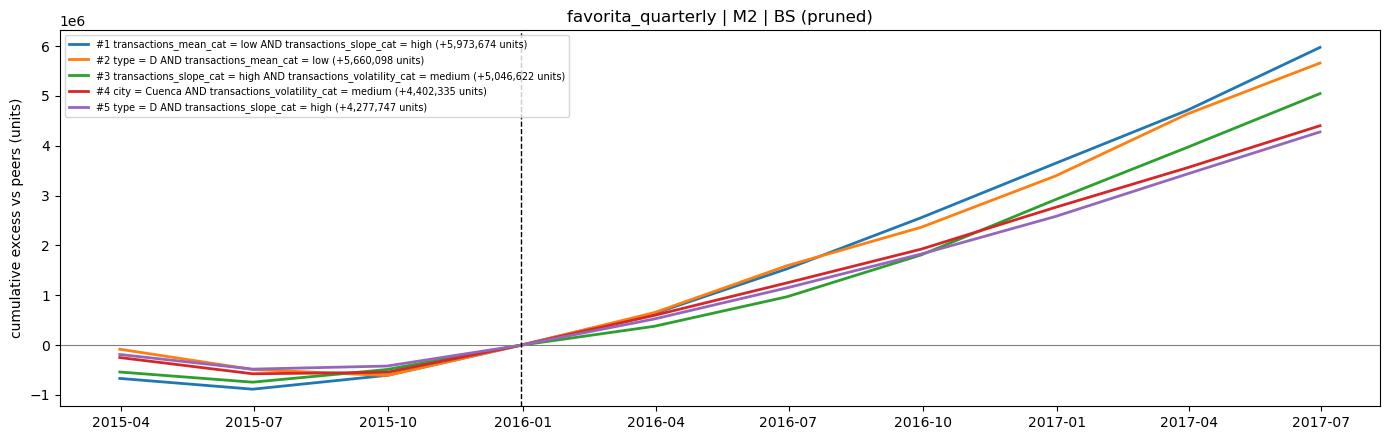

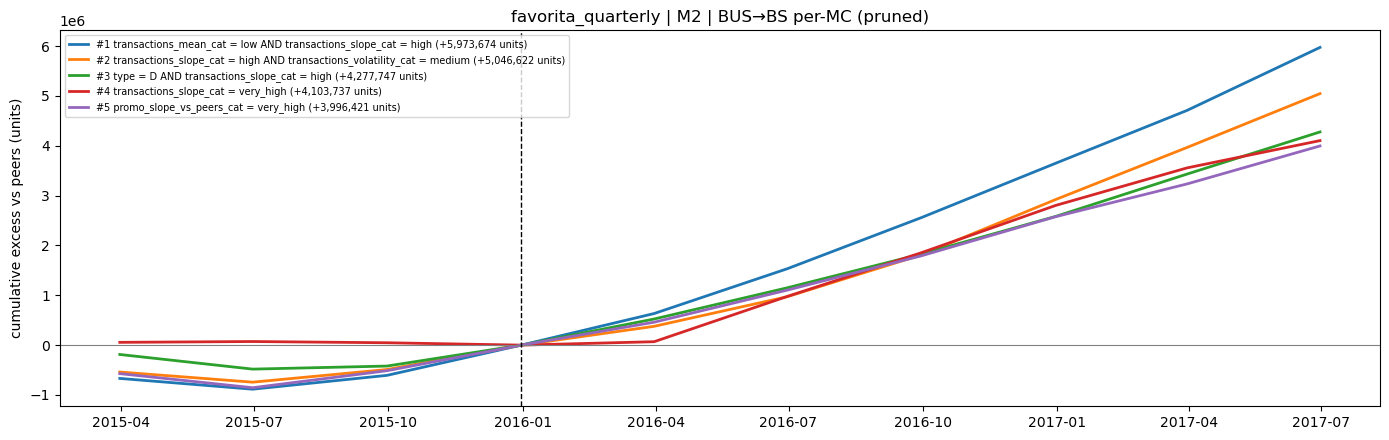

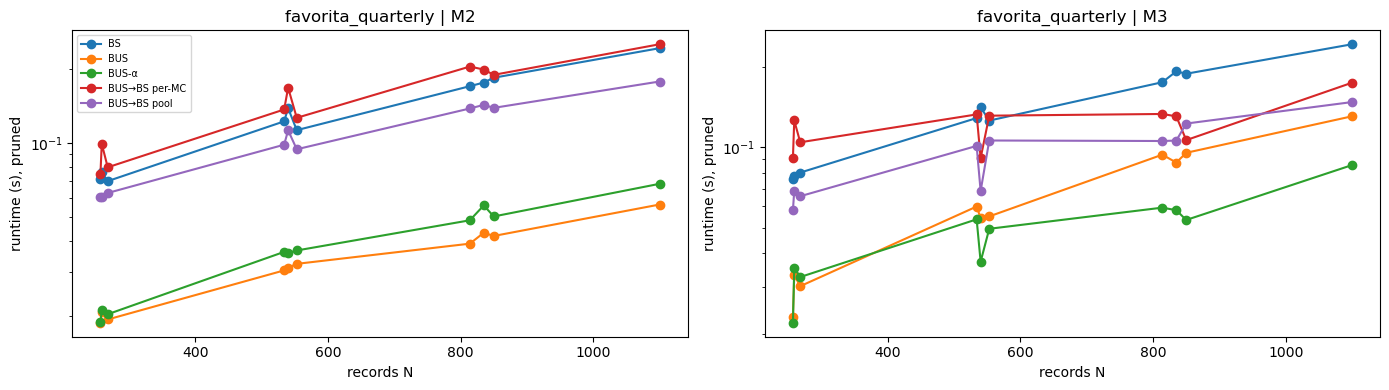

In [13]:
def plot_cumulative_excess(top, phi, k=5, title=""):
    """Running total of each subgroup's relative excess. A steady slope = persistent, subtle deviation;
    a jump = one event. Dashed line = end of the base window."""
    total_excess = excess.sum(axis=0)
    total_level = level.sum()
    fig, ax = plt.subplots(figsize=(14, 4.5))
    for r, (quality, desc, mask) in enumerate(top[:k]):
        E_s = excess[mask].sum(axis=0)
        level_s = level[mask].sum()
        E_s = E_s - level_s * (total_excess - E_s) / (total_level - level_s)
        ax.plot(dates, np.cumsum(E_s), lw=2, label=f"#{r+1} {describe(desc)} ({phi.signed(mask):+,.0f} {UNIT})")
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(dates[BASE_LEN - 1], color="black", ls="--", lw=1)
    ax.set_ylabel(f"cumulative excess vs peers ({UNIT})")
    ax.set_title(title)
    ax.legend(fontsize=7, loc="best")
    plt.tight_layout()
    plt.show()


for method in ("BS", "BUS→BS per-MC"):
    top, stats, pool, phi = main_runs[("M2", method, True)]
    plot_cumulative_excess(top, phi, title=f"{DATASET} | M2 | {method} (pruned)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, measure in zip(axes, ("M2", "M3")):
    sub = scaling_df[(scaling_df["measure"] == measure) & scaling_df["prune"]]
    sub = sub.groupby(["method", "N_sub"])["runtime_s"].mean().reset_index()
    for method, g in sub.groupby("method"):
        ax.plot(g["N_sub"], g["runtime_s"], marker="o", label=method)
    ax.set_xlabel("records N")
    ax.set_ylabel("runtime (s), pruned")
    ax.set_title(f"{DATASET} | {measure}")
    ax.set_yscale("log")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()